# Classification Analysis
## Σύνολο Δεδομένων: Customer Churn 



Στο παρόν notebook υλοποιείται η αρχική εξερεύνηση του dataset με σκοπό να προβλέψουμε αν ένας πελάτης θα διακόψει τις αγορές του από μια διαδικτυακή πλατφόρμα (στήλη-στόχος: `target_event`, όπου 1 = churn και 0 = όχι churn).



### 1) Import the libraries

In [2]:
# Βασικές βιβλιοθήκες για διαχείριση και ανάλυση δεδομένων
import pandas as pd
import numpy as np

# Βιβλιοθήκες για οπτικοποίηση δεδομένων (EDA)
import matplotlib.pyplot as plt
import seaborn as sns

# Εργαλεία για διαχωρισμό σε train/test sets και κλιμάκωση δεδομένων
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler

### 2) Load the data and describe the variables

Το dataset περιλαμβάνει 112.610 εγγραφές και 276 στήλες και αφορά τη συμπεριφορά 21.605 χρηστών μιας διαδικτυακής πλατφόρμας αγορών (σύνοδοι, προβολές προϊόντων, προσθήκες στο καλάθι, αγορές). Συνοδεύεται από ένα λεξικό δεδομένων (`data_dict.csv`) που εξηγεί τι σημαίνει κάθε μεταβλητή.

In [3]:
df = pd.read_csv('customer_model.csv')
print(df.columns.tolist())

['row_id', 'user_id', 'length_mean', 'start_year_mean', 'start_yearday_mean', 'start_month_mean', 'start_monthday_mean', 'start_week_mean', 'start_weekday_mean', 'start_isweekend_mean', 'start_hour_mean', 'haspurchase_mean', 'click_count_mean', 'view_count_mean', 'cart_count_mean', 'purchase_count_mean', 'time_to_click_mean', 'time_to_view_mean', 'time_to_cart_mean', 'time_to_purchase_mean', 'view_revenue_mean', 'cart_revenue_mean', 'purchase_revenue_mean', 'time_to_click_revenue_mean', 'time_to_view_revenue_mean', 'time_to_cart_revenue_mean', 'time_to_purchase_revenue_mean', 'session_number_mean', 'inter_session_time_mean', 'session_recency_mean', 'purchase_number_mean', 'inter_purchase_time_mean', 'purchase_recency_mean', 'length_sum', 'start_year_sum', 'start_yearday_sum', 'start_month_sum', 'start_monthday_sum', 'start_week_sum', 'start_weekday_sum', 'start_isweekend_sum', 'start_hour_sum', 'haspurchase_sum', 'click_count_sum', 'view_count_sum', 'cart_count_sum', 'purchase_count_su

In [4]:
print(df.info())   # πλήθος γραμμών, στήλες, τύποι δεδομένων, μη κενές τιμές
print(df.head())   # πρώτες 5 γραμμές

<class 'pandas.DataFrame'>
RangeIndex: 112610 entries, 0 to 112609
Columns: 276 entries, row_id to target_actual_profit
dtypes: float64(219), int64(57)
memory usage: 237.1 MB
None
   row_id    user_id   length_mean  start_year_mean  start_yearday_mean  \
0      31  522576412  10133.678750        2019.3250           241.65000   
1      53  551695186      5.359195        2019.3620           222.05173   
2      65  561472000      4.885714        2019.0000           297.54285   
3      85  585643355   4175.082759        2019.8966           106.00000   
4     133  520792937      3.325601        2019.3196           212.86598   

   start_month_mean  start_monthday_mean  start_week_mean  start_weekday_mean  \
0          8.400000            16.875000        33.825000            4.225000   
1          7.827586            14.655172        31.448277            4.034483   
2         10.114285            21.000000        43.142857            2.942857   
3          3.931035            17.655172     

#### 2.1) Μεταβλητές-στόχοι



In [5]:
print([c for c in df.columns if c.startswith('target')])

['target_event', 'target_revenue', 'target_customer_value', 'target_customer_value_lag1', 'target_actual_profit']


#### 2.2) Λεξικό δεδομένων



In [6]:
dd = pd.read_csv('data_dict.csv', encoding='cp1252')
dd['Set'] = dd['Set'].ffill()
print(dd.shape)

(46, 4)


Τυπώνουμε ολόκληρο το λεξικό (με πλήρες πλάτος στηλών) για να δούμε την περιγραφή και τη μονάδα μέτρησης κάθε μεταβλητής.

In [7]:
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 250)
print(dd.columns.tolist())
print(dd.to_string())

['Set', 'Attribute', 'Description', 'Variable name']
            Set                              Attribute                                                               Description               Variable name
0     Dependent                            churn event                                          No transaction in future period.                target_event
1     Dependent              retention campaign profit                                      Incremental profit in future period.        target_actual_profit
2       Recency                        session recency                                time duration from the last session [days]             session_recency
3       Recency                       purchase recency                            time duration from the last transaction [days]            purchase_recency
4       Recency                        time to session                                              time between sessions [days]          inter_session_time
5    


Το λεξικό περιγράφει 46 μεταβλητές με τέσσερα πεδία: `Set` (ομάδα), `Attribute` (όνομα), `Description` (περιγραφή και μονάδα μέτρησης) και `Variable name` (το όνομα της στήλης στο dataset).

#### 2.3) Ομάδες μεταβλητών

Μετράμε πόσες μεταβλητές ανήκουν σε κάθε ομάδα.

In [8]:
print(dd['Set'].value_counts())

Set
Frequency      14
Others          9
Date & time     8
Monetary        7
Recency         4
Dependent       2
Preference      2
Name: count, dtype: int64


Εξετάζουμε ενδεικτικά τις ομάδες **Date & time** και **Preference**:

In [9]:
print(dd[dd['Set'].isin(['Date & time', 'Preference'])])

            Set                 Attribute                                                               Description           Variable name
27   Preference      view latent factor *  latent factor characterizing preference manifested through product views      view_latent_factor
28   Preference  purchase latent factor *   latent factor characterizing preference manifested through transactions  purchase_latent_factor
29  Date & time                      year                                                   year of a session start              start_year
30  Date & time                     month                                                  month of a session start             start_month
31  Date & time                      week                                         week of a year of a session start              start_week
32  Date & time               day of year                                          day of a year of a session start           start_yearday
33  Date & time     

In [10]:
print(dd[dd['Set'] == 'Monetary'])

         Set                           Attribute                                           Description               Variable name
20  Monetary                      viewed revenue           potential revenue from viewed products [CU]                view_revenue
21  Monetary               added-to-cart revenue    potential revenue from products added to cart [CU]                cart_revenue
22  Monetary               transactional revenue                  revenue from realized purchases [CU]            purchase_revenue
23  Monetary  transactional revenue, with lags *         monthly transactional revenue, with lags [CU]  purchase_revenue_month_lag
24  Monetary       ma of transactional revenue *  moving average of monthly transactional revenue [CU]   purchase_revenue_month_ma
25  Monetary         customer value, with lags *                monthly customer value, with lags [CU]    customer_value_month_lag
26  Monetary              ma of customer value *   moving average of monthly total 

In [11]:
print(dd[dd['Set'] == 'Others'])

       Set                    Attribute                                                         Description             Variable name
37  Others          time to interaction                         average duration between interactions [min]             time_to_click
38  Others                 time to view                        average duration between product views [min]              time_to_view
39  Others          time to add-to-cart              average duration between adding products to cart [min]              time_to_cart
40  Others             time to purchase                            average duration between purchases [min]          time_to_purchase
41  Others  time to interaction revenue  average duration to interact with a product of value 1 CU [min/CU]     time_to_click_revenue
42  Others         time to view revenue           average duration to view a product of value 1 CU [min/CU]      time_to_view_revenue
43  Others  time to add-to-cart revenue  average duration to a

In [12]:
suffix = df.columns.to_series().str.rsplit('_', n=1).str[-1]
print(suffix.value_counts().head(25))

mean        31
sum         31
min         31
max         31
stddev      31
cv          31
lag1         5
lag0         4
lag2         4
lag3         4
ma3          4
ratio        3
id           2
factor0      2
factor1      2
factor2      2
factor3      2
factor4      2
factor5      2
factor6      2
factor7      2
factor8      2
factor9      2
factor10     2
factor11     2
Name: count, dtype: int64




Οι καταλήξεις `mean`, `sum`, `min`, `max`, `stddev` και `cv` εμφανίζονται από 31 φορές η καθεμία. Αυτό σημαίνει ότι 31 βασικές μεταβλητές έχουν υπολογιστεί με 6 διαφορετικά στατιστικά, δηλαδή 186 από τις 276 στήλες. Οι υπόλοιπες καταλήξεις αντιστοιχούν σε μεταβλητές με χρονικές υστερήσεις (`lag0` έως `lag3`), κινητούς μέσους (`ma3`), ρυθμούς (`ratio`), λανθάνοντες παράγοντες (`factor`) και τα αναγνωριστικά (`id`: `row_id`, `user_id`).

#### 2.4) Αντιστοίχιση των στηλών με το λεξικό δεδομένων



In [13]:
base = dd['Variable name'].str.strip().tolist()
group_of = dict(zip(base, dd['Set']))

def match_base(col):
    # Μακρύτερο όνομα του λεξικού με το οποίο ξεκινά η στήλη
    cands = [b for b in base if col.startswith(b)]
    return max(cands, key=len) if cands else None

cols = pd.DataFrame({'column': df.columns})
cols['base'] = cols['column'].apply(match_base)
cols['group'] = cols['base'].map(group_of)
print(cols['group'].value_counts(dropna=False))

group
Preference     59
Frequency      55
Others         54
Date & time    48
Monetary       28
Recency        24
NaN             6
Dependent       2
Name: count, dtype: int64


Εμφανίζουμε τις στήλες που δεν βρήκαν ομάδα (NaN) και ενδεικτικά τις πρώτες στήλες κάθε ομάδας.

In [14]:
print(cols[cols['group'].isna()]['column'].tolist())

for g, sub in cols.groupby('group'):
    print(g, len(sub), sub['column'].head(6).tolist())

['row_id', 'user_id', 'target_revenue', 'target_customer_value', 'time_step', 'target_customer_value_lag1']
Date & time 48 ['start_year_mean', 'start_yearday_mean', 'start_month_mean', 'start_monthday_mean', 'start_week_mean', 'start_weekday_mean']
Dependent 2 ['target_event', 'target_actual_profit']
Frequency 55 ['haspurchase_mean', 'click_count_mean', 'view_count_mean', 'cart_count_mean', 'purchase_count_mean', 'session_number_mean']
Monetary 28 ['view_revenue_mean', 'cart_revenue_mean', 'purchase_revenue_mean', 'view_revenue_sum', 'cart_revenue_sum', 'purchase_revenue_sum']
Others 54 ['length_mean', 'time_to_click_mean', 'time_to_view_mean', 'time_to_cart_mean', 'time_to_purchase_mean', 'time_to_click_revenue_mean']
Preference 59 ['view_latent_factor0', 'view_latent_factor1', 'view_latent_factor2', 'view_latent_factor3', 'view_latent_factor4', 'view_latent_factor5']
Recency 24 ['inter_session_time_mean', 'session_recency_mean', 'inter_purchase_time_mean', 'purchase_recency_mean', 'i

Η ομάδα **Preference** έχει τις περισσότερες στήλες, οπότε εξετάζουμε από ποιους λανθάνοντες παράγοντες αποτελείται.

In [15]:
pref = cols[cols['group'] == 'Preference']
print(pref['base'].value_counts())
print(pref['column'].tolist())

base
view_latent_factor        41
purchase_latent_factor    18
Name: count, dtype: int64
['view_latent_factor0', 'view_latent_factor1', 'view_latent_factor2', 'view_latent_factor3', 'view_latent_factor4', 'view_latent_factor5', 'view_latent_factor6', 'view_latent_factor7', 'view_latent_factor8', 'view_latent_factor9', 'view_latent_factor10', 'view_latent_factor11', 'view_latent_factor12', 'view_latent_factor13', 'view_latent_factor14', 'view_latent_factor15', 'view_latent_factor16', 'view_latent_factor17', 'view_latent_factor18', 'view_latent_factor19', 'view_latent_factor20', 'view_latent_factor21', 'view_latent_factor22', 'view_latent_factor23', 'view_latent_factor24', 'view_latent_factor25', 'view_latent_factor26', 'view_latent_factor27', 'view_latent_factor28', 'view_latent_factor29', 'view_latent_factor30', 'view_latent_factor31', 'view_latent_factor32', 'view_latent_factor33', 'view_latent_factor34', 'view_latent_factor35', 'view_latent_factor36', 'view_latent_factor37', 'view_la

### 3) Exploratory Data Analysis (EDA)

#### 3.1) Πόσες γραμμές αντιστοιχούν σε κάθε χρήστη;



In [16]:
# Πλήθος μοναδικών χρηστών και στατιστικά του πλήθους γραμμών ανά χρήστη
print(df['user_id'].nunique())
print(df.groupby('user_id').size().describe())

# Όλες οι γραμμές του πρώτου χρήστη
first_user = df['user_id'].iloc[0]
print(df[df['user_id'] == first_user][['user_id', 'start_month_mean', 'target_event']])

21605
count    21605.000000
mean         5.212219
std          1.674962
min          1.000000
25%          4.000000
50%          6.000000
75%          7.000000
max          7.000000
dtype: float64
          user_id  start_month_mean  target_event
0       522576412          8.400000             0
1594    522576412          9.666667             0
58843   522576412         10.750000             0
77383   522576412         11.592592             0
87689   522576412          8.837838             0
108231  522576412         11.083333             0


#### 3.2) Χρονικά βήματα (`time_step`)

Η στήλη `time_step` δείχνει σε ποια χρονική περίοδο αντιστοιχεί κάθε γραμμή. Ελέγχουμε πόσες γραμμές έχει κάθε βήμα και πόσα διαφορετικά βήματα έχει ο κάθε χρήστης.

In [17]:
print('time_step' in df.columns)
print(df['time_step'].value_counts().sort_index())
print(df.groupby('user_id')['time_step'].nunique().describe())   # διαφορετικά βήματα ανά χρήστη

True
time_step
0    21605
1    21030
2    19690
3    17821
4    14975
5    11233
6     6256
Name: count, dtype: int64
count    21605.000000
mean         5.212219
std          1.674962
min          1.000000
25%          4.000000
50%          6.000000
75%          7.000000
max          7.000000
Name: time_step, dtype: float64


#### 3.3) Κατανομή της μεταβλητής-στόχου (`target_event`)

Εξετάζουμε πόσες φορές εμφανίζεται κάθε τιμή (0 και 1) για να διαπιστώσουμε αν το δείγμα μας είναι ισορροπημένο.

In [18]:
print(df['target_event'].value_counts())

target_event
0    76480
1    36130
Name: count, dtype: int64


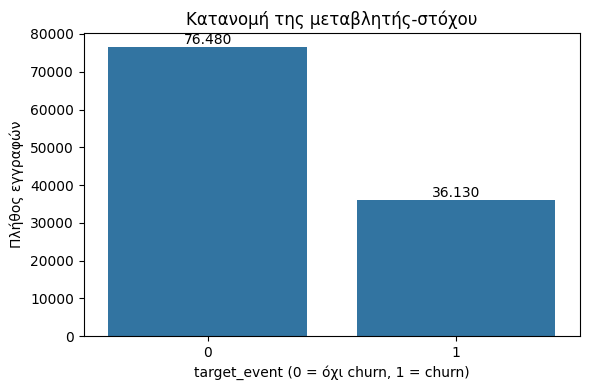

In [19]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x='target_event', data=df, ax=ax)
ax.set_xlabel('target_event (0 = όχι churn, 1 = churn)')
ax.set_ylabel('Πλήθος εγγραφών')
ax.set_title('Κατανομή της μεταβλητής-στόχου')

# Προσθήκη των τιμών πάνω από κάθε μπάρα
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}".replace(',', '.'),
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
plt.tight_layout()
plt.savefig('eikona_3_1.png', dpi=300)
plt.show()

#### 3.4) Σχέση των μεταβλητών recency με το churn

Οι μεταβλητές recency δείχνουν πόσες ημέρες έχουν περάσει από την τελευταία σύνοδο ή αγορά του χρήστη. Υπολογίζουμε τον μέσο όρο όλων των στηλών που περιέχουν τη λέξη `recency` για κάθε τιμή του `target_event`.

In [20]:
rc = [c for c in df.columns if 'recency' in c]
print(df.groupby('target_event')[rc].mean())

              session_recency_mean  purchase_recency_mean  session_recency_sum  purchase_recency_sum  session_recency_min  purchase_recency_min  session_recency_max  purchase_recency_max  session_recency_stddev  purchase_recency_stddev  \
target_event                                                                                                                                                                                                                                  
0                        37.848701              36.503372          2395.204866            901.663477             4.671215              8.872219            73.636262             66.117091               20.106647                18.254602   
1                        71.931148              71.370199          5058.979029           2300.066096            31.650634             37.040739           112.184682            105.788845               22.321443                20.123687   

              session_recency_cv  purchase_

### 4) Data quality check

Πριν τη μοντελοποίηση ελέγχουμε ότι τα δεδομένα είναι πλήρη και κατάλληλα για τους αλγορίθμους: ελλιπείς τιμές, τύποι μεταβλητών, τυχόν placeholder τιμές (-1), διπλότυπες γραμμές, σταθερές στήλες και άπειρες τιμές.

#### 4.1) Ελλιπείς τιμές

Υπολογίζουμε το συνολικό πλήθος κενών τιμών σε ολόκληρο το DataFrame.

In [21]:
print(df.isna().sum().sum())

0


#### 4.2) Τύποι δεδομένων

Ελέγχουμε αν υπάρχουν στήλες που δεν είναι αριθμητικές.

In [22]:
df.select_dtypes(exclude='number').columns   # στήλες που δεν είναι αριθμητικές

Index([], dtype='str')

#### 4.3) Τιμές placeholder (-1)

Σε πολλά dataset η τιμή -1 χρησιμοποιείται για να δηλώσει άγνωστη τιμή. Ελέγχουμε αν εμφανίζεται κάπου.

In [23]:
print((df == -1).sum().sum())

0


#### 4.4) Διπλότυπες γραμμές, σταθερές στήλες και άπειρες τιμές

Ελέγχουμε (1) αν υπάρχουν διπλότυπες γραμμές (αγνοώντας το `row_id`, που είναι μοναδικό σε κάθε γραμμή), (2) αν υπάρχουν στήλες με μία μόνο τιμή σε όλες τις γραμμές και (3) αν υπάρχουν άπειρες τιμές.

In [24]:
# 1. Διπλότυπες γραμμές
print(df.drop(columns='row_id').duplicated().sum())

# 2. Στήλες με μία μόνο τιμή σε όλες τις γραμμές
const_cols = [c for c in df.columns if df[c].nunique() == 1]
print(const_cols)

# 3. Άπειρες τιμές
print(np.isinf(df).sum().sum())

0
['session_number_min', 'purchase_number_min', 'haspurchase_max']
0


### 5) Data preparation, preprocessing, and train/test split

Σε αυτή την ενότητα προετοιμάζουμε τα δεδομένα για τους αλγορίθμους: ορίζουμε τα χαρακτηριστικά (X), τον στόχο (y) και τις ομάδες (groups), αφαιρούμε τις στήλες που δεν χρειάζονται, χωρίζουμε το δείγμα σε σύνολο εκπαίδευσης (train) και ελέγχου (test) ανά χρήστη, επιλέγουμε τα τελικά χαρακτηριστικά (βάσει βιβλιογραφίας και φίλτρου συσχέτισης) και κλιμακώνουμε τις μεταβλητές.

#### 5.1) Επιλογή χαρακτηριστικών (X), στόχου (y) και ομάδων (groups)



In [25]:
# Στήλες που δεν θα χρησιμοποιηθούν ως χαρακτηριστικά
drop_cols = ['target_event', 'target_actual_profit', 'target_revenue',
             'target_customer_value', 'target_customer_value_lag1',
             'row_id', 'user_id', 'time_step']

# Ορισμός y, groups και X
y = df['target_event']
groups = df['user_id']
X = df.drop(columns=drop_cols)

print(X.shape)
print(y.shape)
print(y.value_counts(normalize=True))
print([c for c in X.columns if c.startswith('target')])   # έλεγχος: δεν έχει μείνει στήλη-στόχος

(112610, 268)
(112610,)
target_event
0    0.679158
1    0.320842
Name: proportion, dtype: float64
[]


#### 5.2) Αφαίρεση σταθερών στηλών

Αφαιρούμε τις 3 σταθερές στήλες που εντοπίστηκαν.

In [26]:
print(df[const_cols].iloc[0])
X = X.drop(columns=const_cols)
print(X.shape)

session_number_min     1
purchase_number_min    1
haspurchase_max        1
Name: 0, dtype: int64
(112610, 265)


#### 5.3) Διαχωρισμός σε Training Set και Test Set (ανά χρήστη)

Κάθε χρήστης έχει έως 7 γραμμές. Αν ο διαχωρισμός γινόταν τυχαία ανά γραμμή, γραμμές του ίδιου χρήστη θα βρίσκονταν και στο train και στο test και τα αποτελέσματα θα ήταν υπερβολικά αισιόδοξα. Γι' αυτό χρησιμοποιούμε τον `StratifiedGroupKFold` με 5 folds: όλες οι γραμμές ενός χρήστη πηγαίνουν στο ίδιο σύνολο και ταυτόχρονα διατηρείται η αναλογία των κλάσεων. Παίρνουμε το πρώτο fold ως test set (περίπου 20%) και τα υπόλοιπα ως train set (περίπου 80%). Το `random_state=42` εξασφαλίζει την αναπαραγωγή των αποτελεσμάτων.

In [27]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(sgkf.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train, groups_test = groups.iloc[train_idx], groups.iloc[test_idx]

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))
print(len(set(groups_train) & set(groups_test)))   # κοινοί χρήστες σε train και test
print(groups_train.nunique(), groups_test.nunique())

(90087, 265) (22523, 265)
target_event
0    0.679155
1    0.320845
Name: proportion, dtype: float64
target_event
0    0.679172
1    0.320828
Name: proportion, dtype: float64
0
17293 4312


In [28]:
print(y_train.value_counts())
print(y_test.value_counts())
print((y_train == 0).sum() / (y_train == 1).sum())   # λόγος κλάσης 0 προς κλάση 1

target_event
0    61183
1    28904
Name: count, dtype: int64
target_event
0    15297
1     7226
Name: count, dtype: int64
2.1167658455577083


#### 5.4) Έλεγχος της κλίμακας των μεταβλητών



In [29]:
sd = X_train.std().sort_values()
print(sd.head(3))
print(sd.tail(3))
print(X_train[[sd.index[0], sd.index[-1]]].describe().loc[['min', 'max', 'std']])

start_year_cv                0.000106
time_to_click_revenue_min    0.003882
time_to_view_revenue_min     0.007142
dtype: float64
start_year_sum        256600.501529
length_sum            339914.962523
session_number_sum    971010.076319
dtype: float64
     start_year_cv  session_number_sum
min       0.000000        1.000000e+00
max       0.000350        2.310283e+08
std       0.000106        9.710101e+05


#### 5.5) Επιλογή χαρακτηριστικών βάσει βιβλιογραφίας

 Για να περιορίσουμε την πολυπλοκότητα και τον κίνδυνο overfitting, κρατάμε 12 βασικές μεταβλητές, που επιλέχθηκαν βάσει της βιβλιογραφίας άλλων ερευνών για το churn, και για καθεμία τα 6 στατιστικά της (`mean`, `sum`, `min`, `max`, `stddev`, `cv`). 

In [ ]:
# Βασικές μεταβλητές βάσει βιβλιογραφίας 
literature_bases = ['purchase_recency', 'session_recency', 'purchase_count',
                    'purchase_number', 'purchase_revenue', 'click_count',
                    'session_number', 'length', 'cart_count', 'haspurchase',
                    'start_isweekend', 'start_hour']
stats = ['mean', 'sum', 'min', 'max', 'stddev', 'cv']

# Όλοι οι συνδυασμοί βασικής μεταβλητής και στατιστικού (12 x 6 = 72)
wanted = [f'{b}_{s}' for b in literature_bases for s in stats]
lit_cols = [c for c in wanted if c in X.columns]       # όσες υπάρχουν στο X
missing = [c for c in wanted if c not in X.columns]    # όσες δεν υπάρχουν

print(len(lit_cols))
print(missing)

69
['purchase_number_min', 'session_number_min', 'haspurchase_max']




Από τους 12 × 6 = 72 πιθανούς συνδυασμούς, οι 3 δεν υπάρχουν στο X: `purchase_number_min`, `session_number_min` και `haspurchase_max`. Είναι ακριβώς οι σταθερές στήλες, άρα απομένουν 69 στήλες. Από τις 265 στήλες του X δεν επιλέχθηκαν 196, μεταξύ των οποίων και οι 59 στήλες της ομάδας Preference.

#### 5.6) Φίλτρο συσχέτισης

 Υπολογίζουμε την απόλυτη συσχέτιση Pearson ανάμεσα σε όλα τα ζεύγη και αφαιρούμε κάθε στήλη που έχει συσχέτιση μεγαλύτερη από 0.9 με κάποια προηγούμενη στήλη της λίστας. Ο υπολογισμός γίνεται **μόνο στο train set**, ώστε το test set να μην επηρεάσει την επιλογή.

In [ ]:
# Απόλυτες συσχετίσεις Pearson, υπολογισμένες ΜΟΝΟ στο train set
corr = X_train[lit_cols].corr().abs()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

# Αφαιρούμε τις στήλες με συσχέτιση > 0.9 με κάποια προηγούμενη στήλη
to_drop = [c for c in upper.columns if (upper[c] > 0.9).any()]
final_cols = [c for c in lit_cols if c not in to_drop]

print(len(to_drop), len(final_cols))
print(to_drop)

18 51
['session_recency_mean', 'session_recency_min', 'session_recency_max', 'session_recency_stddev', 'purchase_number_mean', 'purchase_number_max', 'purchase_number_stddev', 'purchase_revenue_cv', 'session_number_mean', 'session_number_max', 'session_number_stddev', 'length_stddev', 'cart_count_stddev', 'haspurchase_sum', 'haspurchase_min', 'haspurchase_cv', 'start_isweekend_sum', 'start_hour_sum']



Αφαιρέθηκαν 18 στήλες και τα τελικά χαρακτηριστικά είναι **51**.

* Αφαιρέθηκαν 4 από τις 6 στήλες `session_recency`, ενώ καμία στήλη `purchase_recency`, που προηγείται στη λίστα.
* Οι μεταβλητές `purchase_recency`, `purchase_count` και `click_count` διατηρήθηκαν ολόκληρες (6 στήλες η καθεμία).
* Οι μεταβλητές `purchase_number`, `session_number` και `haspurchase` περιορίστηκαν σε 2 στήλες η καθεμία.

#### 5.7) Εφαρμογή της επιλογής στα σύνολα και έλεγχος κλίμακας

Κρατάμε τα 51 τελικά χαρακτηριστικά και στο train και στο test set. Στη συνέχεια ελέγχουμε ξανά τις τυπικές αποκλίσεις, αυτή τη φορά μόνο των επιλεγμένων χαρακτηριστικών.

In [32]:
X_train_sel = X_train[final_cols]
X_test_sel = X_test[final_cols]
print(X_train_sel.shape, X_test_sel.shape)

(90087, 51) (22523, 51)


In [33]:
sd = X_train_sel.std().sort_values()
print(sd.head(3))
print(sd.tail(3))
print(X_train_sel[[sd.index[0], sd.index[-1]]].describe().loc[['min', 'max', 'std']])

session_number_cv      0.017606
purchase_number_cv     0.024034
start_isweekend_min    0.084636
dtype: float64
length_max             40088.243355
length_sum            339914.962523
session_number_sum    971010.076319
dtype: float64
     session_number_cv  session_number_sum
min           0.471405        1.000000e+00
max           0.577337        2.310283e+08
std           0.017606        9.710101e+05


#### 5.8) Κλιμάκωση Δεδομένων (Feature Scaling)

Εφαρμόζουμε `StandardScaler`, ώστε κάθε μεταβλητή να έχει μέση τιμή 0 και τυπική απόκλιση 1. Ο scaler προσαρμόζεται (`fit`) μόνο στο train set και στη συνέχεια εφαρμόζεται και στο test set με τις παραμέτρους του train, ώστε να μην περάσει πληροφορία από το test set στην εκπαίδευση.

In [34]:
scaler = StandardScaler()
X_train_sel_scaled = scaler.fit_transform(X_train_sel)   # fit και transform στο train
X_test_sel_scaled = scaler.transform(X_test_sel)         # μόνο transform στο test

# Συνολικός μέσος και τυπική απόκλιση όλων των τιμών
print(X_train_sel_scaled.mean().round(3), X_train_sel_scaled.std().round(3))
print(X_test_sel_scaled.mean().round(3), X_test_sel_scaled.std().round(3))

-0.0 1.0
-0.005 0.953


ονόματα των 51 τελικών χαρακτηριστικών για εκπαίδευση και αξιολόγηση μοντέλων


In [35]:
pd.Series(final_cols, name='feature').to_csv('final_features.csv', index=False)

### 6) Εκπαίδευση, αξιολόγηση και ερμηνεία των μοντέλων

Εκπαιδεύουμε τα τρία μοντέλα (Λογιστική Παλινδρόμηση, Random Forest, XGBoost) στα 51 κλιμακωμένα χαρακτηριστικά του train set. Η ανισορροπία των κλάσεων αντιμετωπίζεται με class weights. Οι υπερπαράμετροι επιλέγονται με `RandomizedSearchCV` (μετρική ROC-AUC) και `StratifiedGroupKFold` ανά χρήστη μέσα στο train set. Το test set χρησιμοποιείται μόνο στην τελική αξιολόγηση.

#### 6.1) Εκπαίδευση με αναζήτηση υπερπαραμέτρων

In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint, uniform

n_iter = 5   # αριθμός δοκιμών ανά μοντέλο 

# Δεδομένα με ονόματα στηλών και λόγος κλάσεων για το XGBoost
X_train_s = pd.DataFrame(X_train_sel_scaled, columns=final_cols)
X_test_s = pd.DataFrame(X_test_sel_scaled, columns=final_cols)
ratio = (y_train == 0).sum() / (y_train == 1).sum()

# Κάθε μοντέλο και το εύρος των υπερπαραμέτρων του
models = {
    'Logistic Regression': (
        LogisticRegression(class_weight='balanced', solver='saga', max_iter=2000, random_state=42),
        {'C': loguniform(1e-3, 1e2), 'penalty': ['l1', 'l2']}),
    'Random Forest': (
        RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
        {'n_estimators': randint(100, 400), 'max_depth': randint(4, 20),
         'min_samples_leaf': randint(5, 100), 'max_features': ['sqrt', 'log2', 0.3]}),
    'XGBoost': (
        XGBClassifier(scale_pos_weight=ratio, eval_metric='logloss', random_state=42, n_jobs=-1),
        {'n_estimators': randint(100, 500), 'learning_rate': loguniform(0.01, 0.3),
         'max_depth': randint(3, 10), 'subsample': uniform(0.6, 0.4),
         'colsample_bytree': uniform(0.5, 0.5)}),
}

# Αναζήτηση με cross-validation ανά χρήστη, μόνο στο train set
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
best = {}
for name, (model, params) in models.items():
    search = RandomizedSearchCV(model, params, n_iter=n_iter, scoring='roc_auc',
                                cv=cv, random_state=42, n_jobs=-1)
    search.fit(X_train_s, y_train, groups=groups_train)
    best[name] = search.best_estimator_
    print(name, '| CV ROC-AUC:', round(search.best_score_, 4), '|', search.best_params_)

c:\Users\maryp\Documents\ΜΕΤΑΠΤΥΧΙΑΚΟ\PYTHON\uoa_py_course\course_venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\maryp\Documents\ΜΕΤΑΠΤΥΧΙΑΚΟ\PYTHON\uoa_py_course\course_venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Logistic Regression | CV ROC-AUC: 0.8554 | {'C': np.float64(0.0745934328572655), 'penalty': 'l1'}
Random Forest | CV ROC-AUC: 0.8984 | {'max_depth': 13, 'max_features': 0.3, 'min_samples_leaf': 91, 'n_estimators': 187}
XGBoost | CV ROC-AUC: 0.8989 | {'colsample_bytree': np.float64(0.9692763545078751), 'learning_rate': np.float64(0.010026522473407051), 'max_depth': 6, 'n_estimators': 376, 'subsample': np.float64(0.8469926038510867)}


#### 6.2) Αξιολόγηση στο test set

In [37]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay)

rows = []
for name, model in best.items():
    proba = model.predict_proba(X_test_s)[:, 1]
    pred = (proba >= 0.5).astype(int)
    rows.append({'Μοντέλο': name,
                 'Accuracy': accuracy_score(y_test, pred),
                 'Precision': precision_score(y_test, pred),
                 'Recall': recall_score(y_test, pred),
                 'F1-score': f1_score(y_test, pred),
                 'ROC-AUC': roc_auc_score(y_test, proba)})

# Σημείο αναφοράς: πρόβλεψη πάντα «όχι churn»
rows.append({'Μοντέλο': 'Baseline (πάντα όχι churn)',
             'Accuracy': (y_test == 0).mean(), 'Precision': 0, 'Recall': 0,
             'F1-score': 0, 'ROC-AUC': 0.5})

results = pd.DataFrame(rows).set_index('Μοντέλο').round(4)
results.to_csv('test_metrics.csv')
results

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Μοντέλο,,,,,
Logistic Regression,0.7994,0.6783,0.7130,0.6952,0.8446
Random Forest,0.8360,0.7387,0.7563,0.7474,0.8921
XGBoost,0.8353,0.7350,0.7610,0.7478,0.8927
Baseline (πάντα όχι churn),0.6792,0.0000,0.0000,0.0000,0.5000


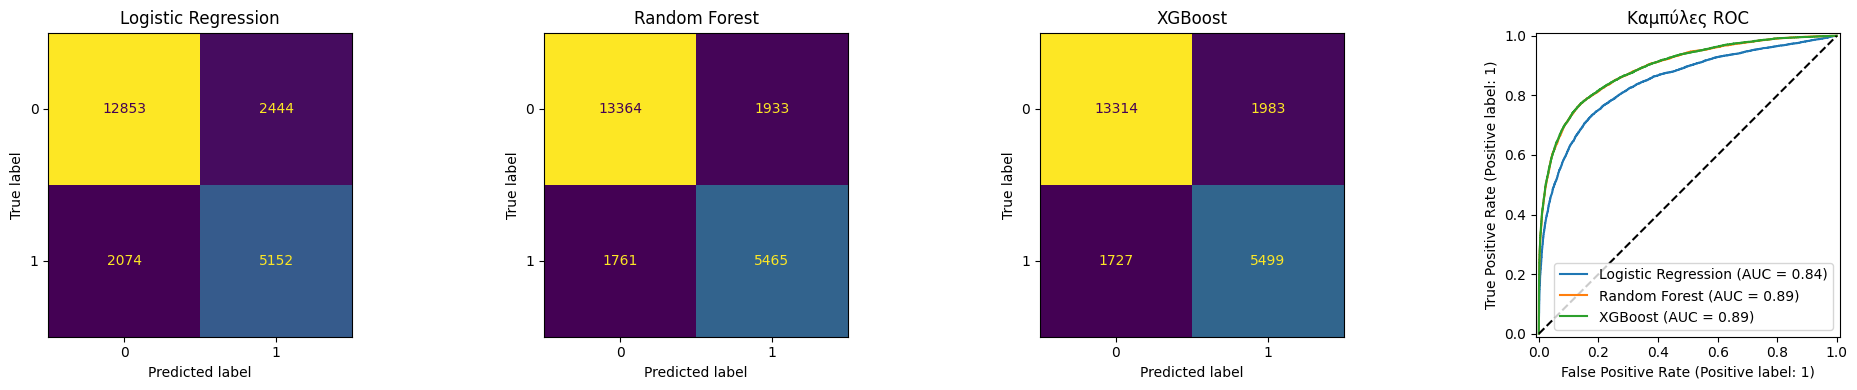

In [38]:
# Πίνακες σύγχυσης και καμπύλες ROC
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (name, model) in zip(axes[:3], best.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test_s, y_test, ax=ax, colorbar=False)
    ax.set_title(name)
for name, model in best.items():
    RocCurveDisplay.from_estimator(model, X_test_s, y_test, name=name, ax=axes[3])
axes[3].plot([0, 1], [0, 1], 'k--')
axes[3].set_title('Καμπύλες ROC')
plt.tight_layout()
plt.savefig('evaluation.png', dpi=200)
plt.show()



Ο πίνακας συγκρίνει τα τρία μοντέλα στο ίδιο test set και με το baseline (accuracy ≈ 67.92%). Οι πίνακες σύγχυσης δείχνουν πόσοι churners εντοπίστηκαν (TP) και πόσοι χάθηκαν (FN), και οι καμπύλες ROC συγκρίνουν τη διακριτική ικανότητα των μοντέλων.

#### 6.3) Ερμηνεία: ποιες μεταβλητές επηρεάζουν το churn

In [40]:
from sklearn.inspection import permutation_importance

# Λογιστική Παλινδρόμηση: συντελεστές (τα χαρακτηριστικά είναι κλιμακωμένα, άρα συγκρίσιμοι)
coef = pd.Series(best['Logistic Regression'].coef_[0], index=final_cols).sort_values()
print('Μεγαλύτεροι θετικοί συντελεστές (αυξάνουν το churn):')
print(coef.tail(5).round(3))
print('Μεγαλύτεροι αρνητικοί συντελεστές (μειώνουν το churn):')
print(coef.head(5).round(3))

# Random Forest και XGBoost: permutation importance στο test set
perm = {}
for name in ['Random Forest', 'XGBoost']:
    r = permutation_importance(best[name], X_test_s, y_test, scoring='roc_auc',
                               n_repeats=5, random_state=42, n_jobs=-1)
    perm[name] = pd.Series(r.importances_mean, index=final_cols).sort_values(ascending=False)
    print('\n' + name)
    print(perm[name].head(10).round(4))

pd.DataFrame(perm).to_csv('permutation_importance.csv')

Μεγαλύτεροι θετικοί συντελεστές (αυξάνουν το churn):
start_hour_cv           0.242
purchase_recency_sum    0.293
purchase_number_cv      0.435
purchase_recency_max    0.521
purchase_recency_min    1.349
dtype: float64
Μεγαλύτεροι αρνητικοί συντελεστές (μειώνουν το churn):
session_recency_cv      -0.523
purchase_recency_mean   -0.379
purchase_recency_cv     -0.224
click_count_stddev      -0.191
start_hour_stddev       -0.171
dtype: float64

Random Forest
purchase_recency_min       0.0908
purchase_number_sum        0.0413
purchase_number_cv         0.0183
session_recency_cv         0.0059
purchase_recency_cv        0.0039
purchase_recency_max       0.0024
purchase_recency_mean      0.0018
purchase_count_sum         0.0012
purchase_recency_sum       0.0009
purchase_recency_stddev    0.0005
dtype: float64

XGBoost
purchase_number_sum      0.1166
purchase_recency_min     0.1109
purchase_number_cv       0.0144
session_recency_cv       0.0073
purchase_recency_max     0.0039
purchase_recency_m